In [51]:
from sklearn.datasets import make_regression
import numpy as np

In [52]:
x,y = make_regression(n_samples=4,n_features=1,n_targets=1,n_informative=1,noise=69,random_state=21)

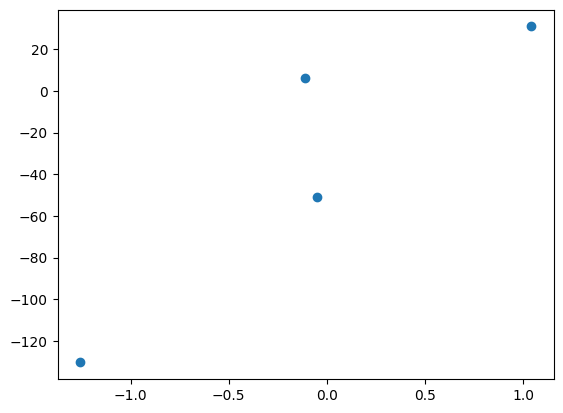

In [53]:
import matplotlib.pyplot as plt
plt.scatter(x,y)

In [54]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [55]:
lr.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [56]:
lr.coef_

array([69.71338159])

In [57]:
lr.intercept_

np.float64(-29.393815457259493)

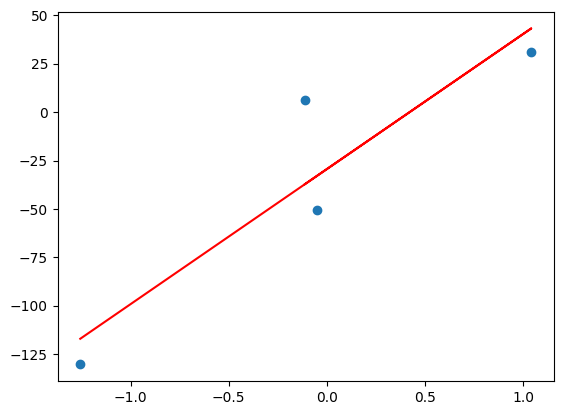

In [58]:
plt.scatter(x,y)
plt.plot(x,lr.predict(x),color='red')

In [59]:

# Lets apply Gradient Descent assuming slope is constant m = 78.35
# and let's assume the starting value for intercept b = 11
y_pred = ((69.71 * x) + 11).reshape(4)

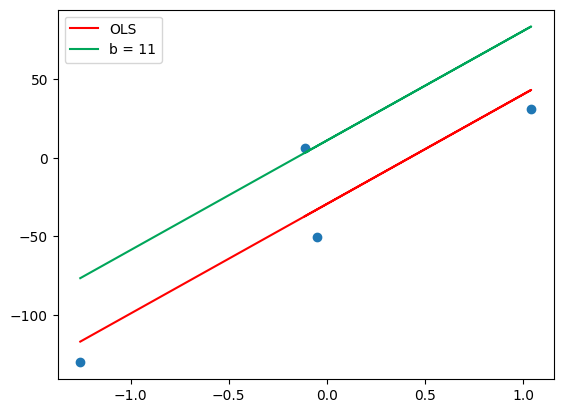

In [60]:

plt.scatter(x,y)
plt.plot(x,lr.predict(x),color='red',label='OLS')
plt.plot(x,y_pred,color='#00a65a',label='b = 11')
plt.legend()
plt.show()

In [61]:
m = 69.71
b = 11

loss_slope = -2 * np.sum(y - m*x.ravel() - b)
loss_slope

np.float64(323.15308083685795)

In [62]:

# Lets take learning rate = 0.1
n = 0.1

step_size = loss_slope*n
step_size

np.float64(32.3153080836858)

In [63]:

# Calculating the new intercept
b = b - step_size
b

np.float64(-21.3153080836858)

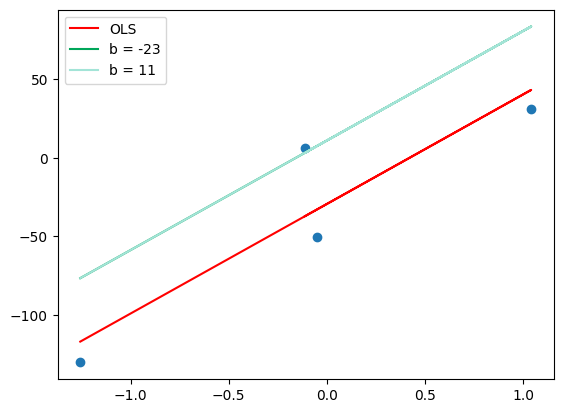

In [70]:

y_pred1 = (( 69.71 * x) + b).reshape(4)

plt.scatter(x,y)
plt.plot(x,lr.predict(x),color='red',label='OLS')
plt.plot(x,y_pred,color='#00a65a',label='b = -23')
plt.plot(x,y_pred,color='#A3E4D7',label='b = 11')
plt.legend()
plt.show()

In [72]:

# Iteration 2
loss_slope = -2 * np.sum(y - m*x.ravel() - b)
loss_slope

np.float64(64.63061616737157)

In [74]:

step_size = loss_slope*n
step_size
     

np.float64(6.463061616737157)

In [75]:

b = b - step_size
b

np.float64(-27.778369700422957)

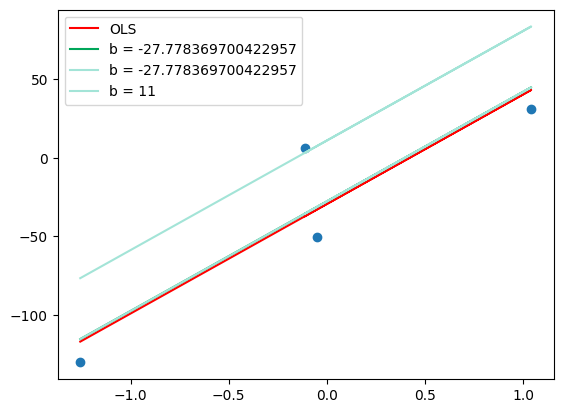

In [77]:

y_pred2 = (( 69.71 * x) + b).reshape(4)

plt.scatter(x,y)
plt.plot(x,lr.predict(x),color='red',label='OLS')
plt.plot(x,y_pred2,color='#00a65a',label='b = {}'.format(b))
plt.plot(x,y_pred1,color='#A3E4D7',label='b = {}'.format(b))
plt.plot(x,y_pred,color='#A3E4D7',label='b = 11')
plt.legend()
plt.show()

In [78]:

# Iteration 3
loss_slope = -2 * np.sum(y - m*x.ravel() - b)
loss_slope

np.float64(12.926123233474314)

In [79]:

step_size = loss_slope*n
step_size
     

np.float64(1.2926123233474316)

In [80]:
b = b - step_size
b

np.float64(-29.070982023770387)

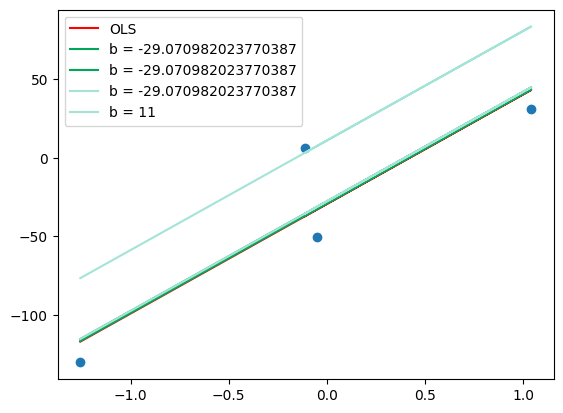

In [81]:
y_pred3 = (( 69.71 * x) + b).reshape(4)

plt.scatter(x,y)
plt.plot(x,lr.predict(x),color='red',label='OLS')
plt.plot(x,y_pred3,color='#00a65a',label='b = {}'.format(b))
plt.plot(x,y_pred2,color='#00a65a',label='b = {}'.format(b))
plt.plot(x,y_pred1,color='#A3E4D7',label='b = {}'.format(b))
plt.plot(x,y_pred,color='#A3E4D7',label='b = 11')
plt.legend()
plt.show()

## Now Use loop for multiple iteration

-223.5153080836858
-68.21836970042295
-37.158982023770385
-30.947104488439873
-29.704728981373773
-29.456253879960553
-29.406558859677908
-29.396619855621378
-29.394632054810074
-29.39423449464781


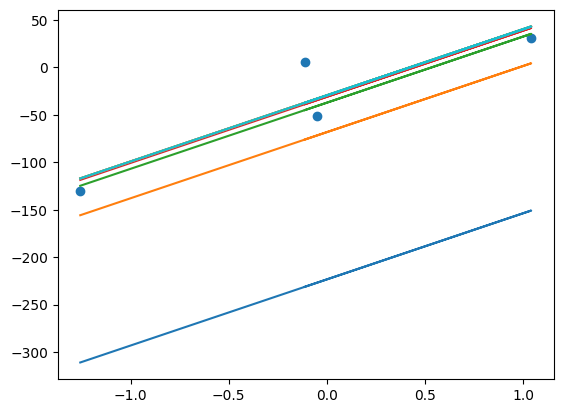

In [90]:
m = 69.71
b = -1000
epochs = 10
n = 0.1
for i in range(epochs):
    loss_slope = -2 * np.sum(y - m*x.ravel() - b)
    b = b - (n * loss_slope)
    print(b)
    y_pred = m*x + b
    plt.plot(x,y_pred)
plt.scatter(x,y)